# 01 - Goal Classifier (baseline)
**Task:** goal text (Hinglish/English) -> career (Web Developer / Data Scientist / Software Engineer)

Plan: compare 3 TF-IDF variants + Logistic Regression, evaluate with cross-validation
(data is small, so a single train/test split can mislead), study confidence, then save the best model.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline, make_pipeline, make_union
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = Path("../data") if Path("../data").exists() else Path("data")
df = pd.read_csv(DATA_DIR / "goal_texts.csv")
X, y = df["text"], df["career"]
print(df.shape)
df["career"].value_counts()

(122, 2)


career
Web Developer        42
Software Engineer    41
Data Scientist       39
Name: count, dtype: int64

## 1. Compare feature types
- **word**: TF-IDF on words (1-2 word phrases)
- **char**: TF-IDF on character n-grams (handles spelling variations like "seekhna/sikhna" and Hinglish)
- **word+char**: both combined

`DummyClassifier` (always predicts the most common class) is the "no ML" baseline.

In [2]:
def word_tfidf():
    return TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)

def char_tfidf():
    return TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)

candidates = {
    "Dummy (most frequent)": make_pipeline(word_tfidf(), DummyClassifier(strategy="most_frequent")),
    "word TF-IDF + LogReg": make_pipeline(word_tfidf(), LogisticRegression(C=10, max_iter=1000)),
    "char TF-IDF + LogReg": make_pipeline(char_tfidf(), LogisticRegression(C=10, max_iter=1000)),
    "word+char + LogReg": make_pipeline(make_union(word_tfidf(), char_tfidf()),
                                        LogisticRegression(C=10, max_iter=1000)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in candidates.items():
    s = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"model": name,
                 "accuracy": s["test_accuracy"].mean(), "acc_std": s["test_accuracy"].std(),
                 "f1_macro": s["test_f1_macro"].mean()})
results = pd.DataFrame(rows).round(3)
results

,model,accuracy,acc_std,f1_macro
0,Dummy (most frequent),0.336,0.013,0.168
1,word TF-IDF + LogReg,0.863,0.118,0.860
2,char TF-IDF + LogReg,0.887,0.099,0.883
3,word+char + LogReg,0.912,0.096,0.907


## 2. Detailed look at the best model
Cross-validated predictions: every sentence is predicted by a model that did not see it.

Best: word+char + LogReg
                   precision    recall  f1-score   support

   Data Scientist       0.87      0.87      0.87        39
Software Engineer       0.88      0.88      0.88        41
    Web Developer       0.98      0.98      0.98        42

         accuracy                           0.91       122
        macro avg       0.91      0.91      0.91       122
     weighted avg       0.91      0.91      0.91       122



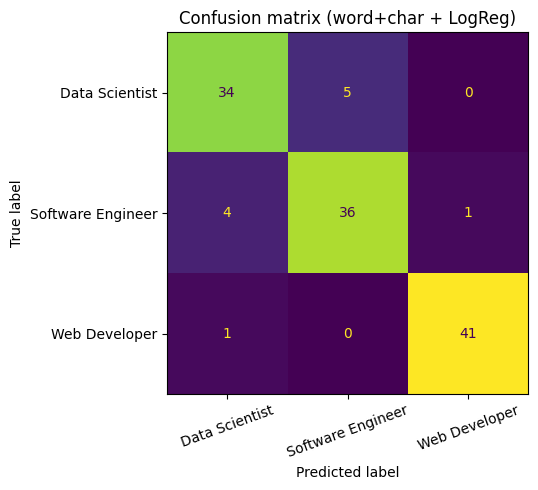

In [3]:
best_name = results.iloc[1:].sort_values(["f1_macro", "accuracy"], ascending=False).iloc[0]["model"]
best = candidates[best_name]
print("Best:", best_name)

pred = cross_val_predict(best, X, y, cv=cv)
print(classification_report(y, pred))

labels = sorted(y.unique())
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=labels), display_labels=labels).plot(ax=ax, xticks_rotation=20, colorbar=False)
plt.title(f"Confusion matrix ({best_name})")
plt.tight_layout()
plt.savefig("confusion_matrix_goal_classifier.png", dpi=150)
plt.show()

### Which sentences did it get wrong?
Wrong predictions show where careers overlap or where the data needs more examples.

In [4]:
wrong = df[pred != y].copy()
wrong["predicted"] = pred[pred != y]
wrong[["text", "career", "predicted"]]

,text,career,predicted
9,I am interested in designing and building web ...,Web Developer,Data Scientist
48,mujhe AI aur ML mein career banana hai,Data Scientist,Software Engineer
64,I want to be an ML engineer,Data Scientist,Software Engineer
67,mujhe Kaggle competitions mein participate kar...,Data Scientist,Software Engineer
68,I want to learn how recommendation systems are...,Data Scientist,Software Engineer
76,mujhe analytics mein career banana hai,Data Scientist,Software Engineer
86,I want to improve my data structures and algor...,Software Engineer,Data Scientist
90,I want to learn computer science fundamentals,Software Engineer,Data Scientist
91,mujhe core CS subjects seekhne hain,Software Engineer,Data Scientist
95,mujhe backend developer banna hai,Software Engineer,Web Developer


## 3. Confidence: when should the website ask the user to confirm?
For each confidence threshold: how many predictions are accepted automatically (coverage),
and how accurate are those? Below the threshold the UI asks the user (`needs_confirmation`).

In [5]:
proba = cross_val_predict(best, X, y, cv=cv, method="predict_proba")
classes = sorted(y.unique())
top_conf = proba.max(axis=1)
top_pred = np.array(classes)[proba.argmax(axis=1)]

rows = []
for t in [0.4, 0.5, 0.6, 0.7, 0.8]:
    m = top_conf >= t
    rows.append({"threshold": t, "coverage": m.mean(),
                 "accuracy_on_accepted": (top_pred[m] == y.values[m]).mean() if m.any() else np.nan})
pd.DataFrame(rows).round(3)

,threshold,coverage,accuracy_on_accepted
0,0.4,0.984,0.917
1,0.5,0.902,0.955
2,0.6,0.852,0.962
3,0.7,0.721,0.977
4,0.8,0.549,1.000


## 4. Try your own sentences
Includes ambiguous ones on purpose. Edit this list and re-run.

In [6]:
best.fit(X, y)   # fit on all data for the demo below

def predict_goal(text, top_k=2):
    p = best.predict_proba([text])[0]
    order = np.argsort(p)[::-1][:top_k]
    return [(best.classes_[i], round(float(p[i]), 3)) for i in order]

tests = [
    "mujhe websites banane hain",
    "I want to build ML models",
    "mujhe Google mein job chahiye",
    "mujhe backend aur APIs seekhni hain",
    "mujhe coding aati hai ab job chahiye",
    "I like data and charts",
    "mujhe kuch samajh nahi aa raha career ke baare mein",
]
for t in tests:
    print(f"{t!r:55} -> {predict_goal(t)}")

'mujhe websites banane hain'                            -> [('Web Developer', 0.97), ('Software Engineer', 0.017)]
'I want to build ML models'                             -> [('Data Scientist', 0.808), ('Web Developer', 0.118)]
'mujhe Google mein job chahiye'                         -> [('Software Engineer', 0.592), ('Data Scientist', 0.238)]
'mujhe backend aur APIs seekhni hain'                   -> [('Software Engineer', 0.906), ('Data Scientist', 0.064)]
'mujhe coding aati hai ab job chahiye'                  -> [('Software Engineer', 0.646), ('Data Scientist', 0.177)]
'I like data and charts'                                -> [('Data Scientist', 0.858), ('Web Developer', 0.075)]
'mujhe kuch samajh nahi aa raha career ke baare mein'   -> [('Software Engineer', 0.48), ('Data Scientist', 0.429)]


## 5. Save the model
The backend will load this file with `joblib.load`.

In [7]:
Path("models").mkdir(exist_ok=True)
joblib.dump(best, "models/goal_classifier.joblib")
print("saved: models/goal_classifier.joblib")

saved: models/goal_classifier.joblib
